In [17]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import silhouette_score, adjusted_rand_score

plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.2})
SEED = 42
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.12.10
NumPy: 2.5.2 pandas: 3.0.6
Scikit-learn: 1.9.1


## 1. Объект, признак, вектор и кластер
Один игрок — **объект**, его часы игры и число матчей — **признаки**.
Строка `[2, 4]` — вектор из двух чисел. На графике он становится точкой `(2, 4)`.
**Кластер** — найденная группа похожих объектов. Готовые правильные номера групп мы алгоритму не сообщаем.

**Перед запуском:** сколько групп вы ожидаете увидеть? Важно: взгляд на двумерный график — подсказка, а не доказательство единственно верного разбиения.

Очікую побачити 2 групи, адже:


на графіку дві області точок

ліва:
    Аня, Борис, Віка
    2-3 години гри, 4-6 матчів

права:
    Гліб, Даша, Єгор
        9-10 годин гри, 18-21 матчів

розрив за годинами та матчами приблинзо у 6 одиниць; це більше, ніж усередині кожної групи. Якщо хтось виріщить, що Борис ділить один кластер з Аннею/Вікою, а Єгор з Глібом/Дашею, то можна створити третю групу. Але це буде не структура даних, а суб'єктивна інтерпретація; для справжнього формувалння третьої групи треба розрив між значеннями

Игрок  Часы  Матчи
  Аня     2      4
Борис     3      5
 Вика     2      6
 Глеб     9     18
 Даша    10     19
 Егор     9     21


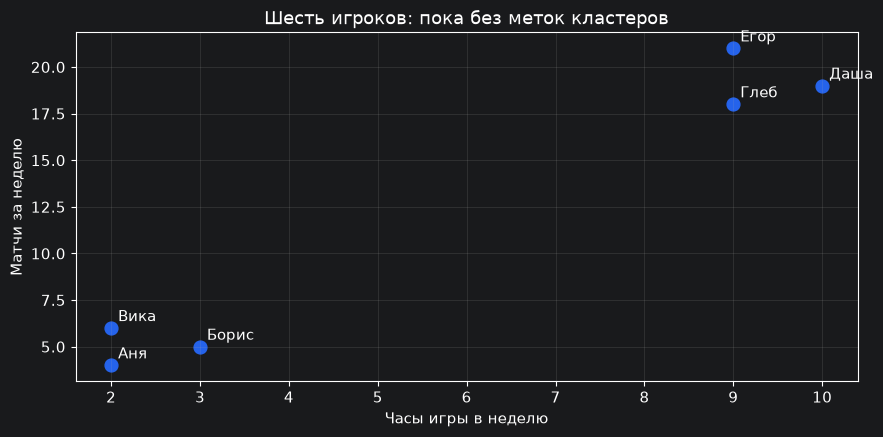

In [18]:
players = pd.DataFrame({
    "Игрок": ["Аня", "Борис", "Вика", "Глеб", "Даша", "Егор"],
    "Часы": [2, 3, 2, 9, 10, 9],
    "Матчи": [4, 5, 6, 18, 19, 21],
})
print(players.to_string(index=False))
plt.figure()
plt.scatter(players["Часы"], players["Матчи"], s=85, color="#2563eb")
for row in players.itertuples(index=False, name=None):
    name, hours, matches = row
    plt.annotate(name, (hours, matches), xytext=(5, 5), textcoords="offset points")
plt.xlabel("Часы игры в неделю")
plt.ylabel("Матчи за неделю")
plt.title("Шесть игроков: пока без меток кластеров")
plt.tight_layout()
plt.show()

**После запуска:** видны две области по активности. Алгоритм пока ничего не делал: мы лишь построили график.
Имена не используем для расстояния — имя не является мерой активности.

## 2. Расстояние и масштаб признаков
Сначала расстояние между `(1, 2)` и `(4, 6)`:
разности 3 и 4, расстояние `sqrt(3² + 4²) = 5`.
Затем проверим, почему деньги могут подавить число покупок при сравнении клиентов.

In [19]:
a = np.array([1.0, 2.0])
b = np.array([4.0, 6.0])
print("Расстояние между A и B:", np.sqrt(np.sum((a - b) ** 2)))

# Клиенты различаются по двум признакам разных масштабов.
scale_demo = pd.DataFrame({
    "Заказы": [1, 2, 9, 10],
    "Деньги": [100, 9000, 150, 9500],
})
scaler_demo = StandardScaler()
scaled_demo = scaler_demo.fit_transform(scale_demo)
print("\nИсходные значения:")
print(scale_demo.to_string(index=False))
print("\nПосле стандартизации:")
print(pd.DataFrame(scaled_demo, columns=scale_demo.columns).round(3).to_string(index=False))
print("\nСреднее каждого преобразованного столбца:", scaled_demo.mean(axis=0).round(5))
print("Стандартное отклонение:", scaled_demo.std(axis=0).round(5))

raw_parts = (scale_demo.iloc[0].to_numpy() - scale_demo.iloc[1].to_numpy()) ** 2
scaled_parts = (scaled_demo[0] - scaled_demo[1]) ** 2
print("\nВклад признаков в квадрат расстояния, до:", raw_parts)
print("Вклад признаков в квадрат расстояния, после:", scaled_parts.round(3))

Расстояние между A и B: 5.0

Исходные значения:
 Заказы  Деньги
      1     100
      2    9000
      9     150
     10    9500

После стандартизации:
 Заказы  Деньги
 -1.116  -1.005
 -0.868   0.944
  0.868  -0.994
  1.116   1.054

Среднее каждого преобразованного столбца: [0. 0.]
Стандартное отклонение: [1. 1.]

Вклад признаков в квадрат расстояния, до: [       1 79210000]
Вклад признаков в квадрат расстояния, после: [0.062 3.799]


**Что заметить:** стандартизация вычисляет `(значение - среднее) / стандартное отклонение` отдельно по столбцам.
Отрицательное значение означает «ниже среднего», а не отрицательное число реальных заказов.
Она выравнивает шкалы, но не делает любые два признака одинаково полезными.

## 3. K-means вручную: назначаем группы и двигаем центры
Точки на линии: `[1, 2, 3, 9, 10, 11]`. Задаём `K = 2`, начальные центры — `1` и `9`.
Для каждой точки выбираем ближайший центр, затем вычисляем среднее своей группы.

**Предскажите:** новыми центрами должны стать `2` и `10`.

Початковими центрами є 1 та 9.

Для кожної точки обчислюємо відстань до центрів за формулою `|x - center|`, обираємо меншу відстань і присвоюємо групу:

1 -> 0 і 8 -> 0;
2 -> 1 i 8 -> 0;
3 -> 2 і 6 -> 0;
9 -> 8 і 0 -> 1;
10 -> 9 і 1 -> 1;
11 -> 10 і 2 -> 1;

Для гр. 0: (1+2+3)/3=2;
Для гр. 1: (9+10+11)/3=10

Точки симетричні навколо нових центрів, тому: 1, 2, 3 ближчі до 2, ніж до 10; 11 ближча до 10, ніж до 2. Отже, нові центри: 2 і 10

Сума квадратів відхилень усередині групи: (1-2)^2+(2-2)^2+(3-2)^2+(9-10)^2+(10-10)^2+(11-10)²=1+0+1+1+0+1=4


 Покупки  До центра 1  До центра 9  Группа
     1.0          0.0          8.0       0
     2.0          1.0          7.0       0
     3.0          2.0          6.0       0
     9.0          8.0          0.0       1
    10.0          9.0          1.0       1
    11.0         10.0          2.0       1
Новые центры: [ 2. 10.]
Назначения изменились после пересчёта? False
Сумма квадратов расстояний до новых центров: 4.0


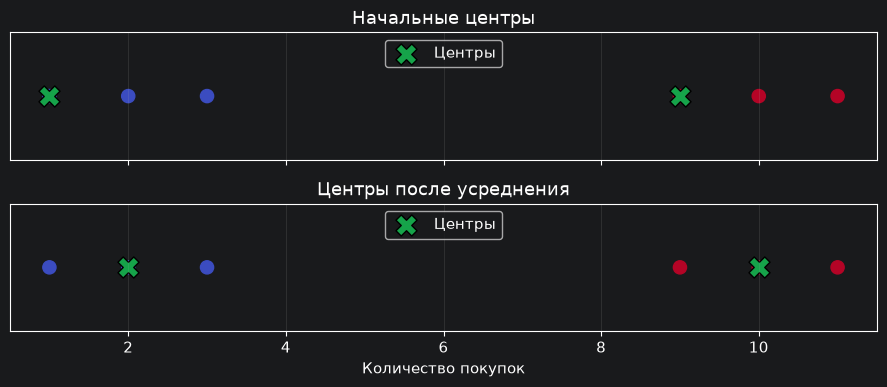

In [20]:
purchases = np.array([1., 2., 3., 9., 10., 11.])
initial_centers = np.array([1., 9.])
distances = np.abs(purchases[:, None] - initial_centers[None, :])
manual_labels = distances.argmin(axis=1)
manual_centers = np.array([
    purchases[manual_labels == group].mean() for group in range(2)
])
manual_table = pd.DataFrame({
    "Покупки": purchases,
    "До центра 1": distances[:, 0],
    "До центра 9": distances[:, 1],
    "Группа": manual_labels,
})
print(manual_table.to_string(index=False))
print("Новые центры:", manual_centers)
next_labels = np.abs(purchases[:, None] - manual_centers[None, :]).argmin(axis=1)
print("Назначения изменились после пересчёта?", not np.array_equal(manual_labels, next_labels))
manual_inertia = np.sum((purchases - manual_centers[manual_labels]) ** 2)
print("Сумма квадратов расстояний до новых центров:", manual_inertia)

fig, axes = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
for ax, centers, title in zip(axes, [initial_centers, manual_centers],
                            ["Начальные центры", "Центры после усреднения"]):
    ax.scatter(purchases, np.zeros(len(purchases)), c=manual_labels, cmap="coolwarm", s=90)
    ax.scatter(centers, [0, 0], marker="X", s=230, color="#16a34a", edgecolors="black", label="Центры")
    ax.set_yticks([])
    ax.set_title(title)
    ax.legend(loc="upper center")
axes[-1].set_xlabel("Количество покупок")
plt.tight_layout()
plt.show()

**Разбор NumPy:** `[:, None]` превращает список из 6 значений в столбец 6×1.
`[None, :]` делает строку центров 1×2. При вычитании NumPy получает расстояния каждой точки до обоих центров.
`argmin(axis=1)` выбирает номер минимального расстояния в каждой строке.
Это короткая запись расчёта из конспекта; для понимания алгоритма достаточно таблицы.

## 4. Тот же расчёт в Scikit-learn
Для проверки берём те же стартовые центры. В обычных задачах чаще используют встроенную инициализацию `k-means++`.

In [21]:
X_line = purchases.reshape(-1, 1)  # Шесть объектов, один признак.
line_model = KMeans(n_clusters=2, init=initial_centers.reshape(-1, 1),
                    n_init=1, random_state=SEED)
line_labels = line_model.fit_predict(X_line)
print("Метки:", line_labels)
print("Центры:", line_model.cluster_centers_.ravel())
print("Inertia:", line_model.inertia_)
print("Итерации:", line_model.n_iter_)
assert np.allclose(np.sort(line_model.cluster_centers_.ravel()), [2, 10])
assert np.isclose(line_model.inertia_, 4)

# Новый объект присоединяется к ближайшему УЖЕ найденному центру.
new_group = line_model.predict([[8]])[0]
print("8 покупок -> группа", new_group, "с центром", line_model.cluster_centers_[new_group, 0])

Метки: [0 0 0 1 1 1]
Центры: [ 2. 10.]
Inertia: 4.0
Итерации: 2
8 покупок -> группа 1 с центром 10.0


`fit` — найти центры; `predict` — назначить группу по уже найденным центрам;
`fit_predict` — обучиться и вернуть метки исходных объектов.
Метки — номера, а не рейтинг качества группы. `predict` не передвигает центры.

## 5. K-means на двух признаках и выбор K
Создаём 240 искусственных точек с тремя облаками. Настоящих клиентов здесь пока нет.
При обучении не передаём исходные метки генератора.

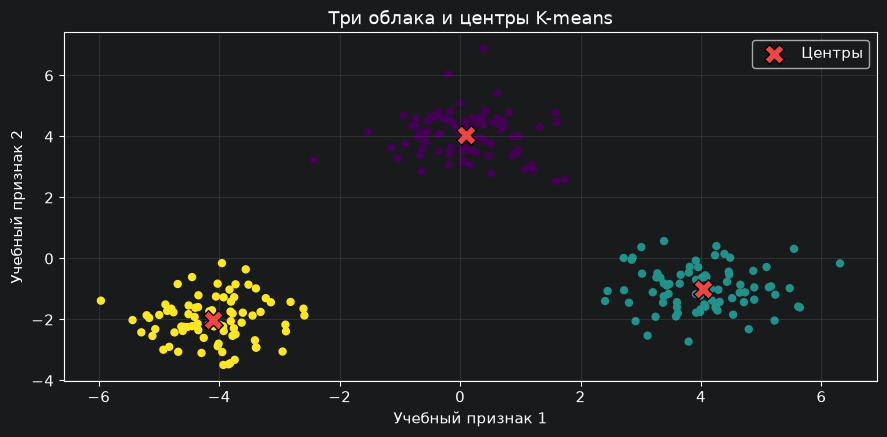

In [22]:
X_clouds, _ = make_blobs(n_samples=240, centers=[[-4, -2], [0, 4], [4, -1]],
                        cluster_std=0.75, random_state=SEED)
cloud_model = KMeans(n_clusters=3, n_init=10, random_state=SEED)
cloud_labels = cloud_model.fit_predict(X_clouds)
plt.figure()
plt.scatter(X_clouds[:, 0], X_clouds[:, 1], c=cloud_labels, cmap="viridis", s=25)
plt.scatter(cloud_model.cluster_centers_[:, 0], cloud_model.cluster_centers_[:, 1],
            marker="X", s=200, c="#ef4444", edgecolors="black", label="Центры")
plt.xlabel("Учебный признак 1")
plt.ylabel("Учебный признак 2")
plt.title("Три облака и центры K-means")
plt.legend()
plt.tight_layout()
plt.show()

**Inertia** — сумма квадратов расстояний до центров. Меньше означает компактнее при данном разбиении,
но большее K обычно само по себе уменьшает эту сумму. Ищем «локоть», после которого выигрыш замедляется.

**Silhouette** сравнивает расстояния до своих и чужих объектов.
Близко к 1 — свои намного ближе; около 0 — группы перекрываются; отрицательные значения — чужие могут быть ближе.
Метрика не подтверждает бизнес-смысл групп. Вычисляем её только при `2 <= число групп < число объектов`.

 K  Inertia  Silhouette
 1 4576.531         NaN
 2 1888.998       0.610
 3  256.949       0.803
 4  224.795       0.643
 5  195.525       0.472
 6  166.406       0.321
 7  147.752       0.327


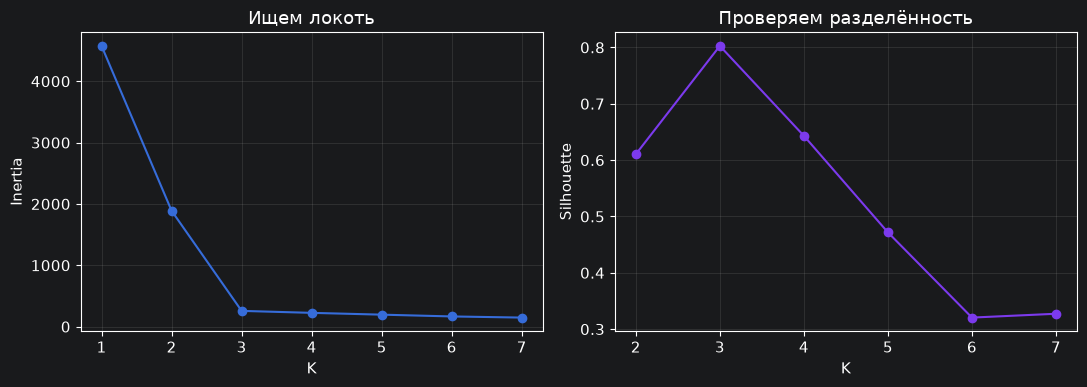

In [23]:
k_rows = []
for k in range(1, 8):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = candidate.fit_predict(X_clouds)
    count = len(np.unique(labels))
    score = silhouette_score(X_clouds, labels) if 2 <= count < len(labels) else np.nan
    k_rows.append({"K": k, "Inertia": candidate.inertia_, "Silhouette": score})
k_results = pd.DataFrame(k_rows)
print(k_results.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_results["K"], k_results["Inertia"], "o-")
axes[0].set(title="Ищем локоть", xlabel="K", ylabel="Inertia")
axes[1].plot(k_results["K"], k_results["Silhouette"], "o-", color="#7c3aed")
axes[1].set(title="Проверяем разделённость", xlabel="K", ylabel="Silhouette")
plt.tight_layout()
plt.show()

**Ожидаемое наблюдение:** три группы хорошо соответствуют устройству этих учебных данных.
K=7 может дать меньшую inertia, но раздробить уже понятные облака.

**Попробуйте:** измените `cluster_std=0.75` на `1.8` в генераторе и повторите раздел 5.
Объясните, почему группы стало труднее разделять. Затем верните исходное значение.

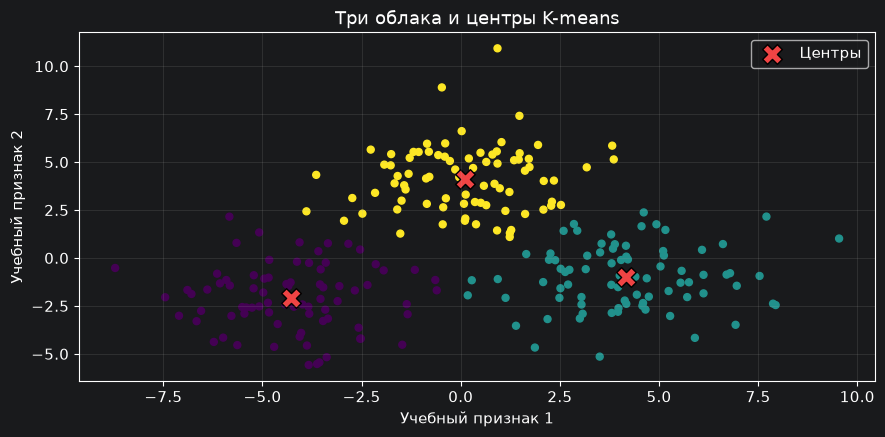

 K  Inertia  Silhouette
 1 5953.724         NaN
 2 3050.720       0.463
 3 1350.484       0.552
 4 1162.558       0.451
 5 1000.455       0.366
 6  874.569       0.366
 7  745.416       0.334


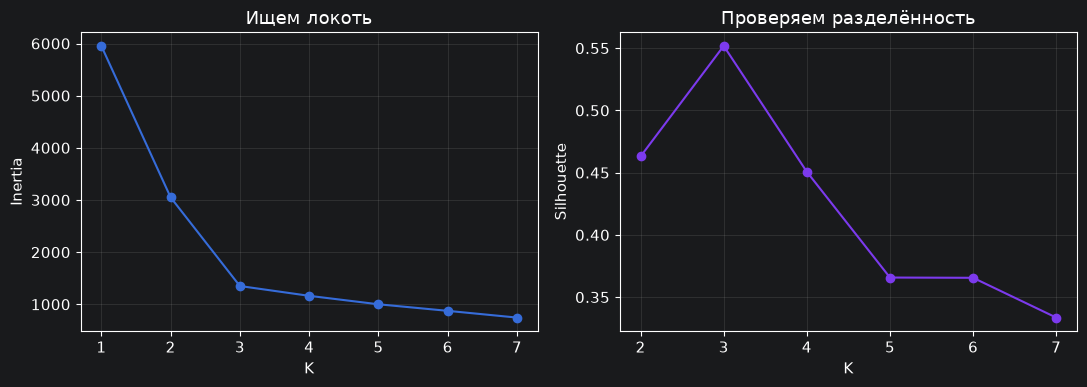

In [24]:
X_clouds, _ = make_blobs(n_samples=240, centers=[[-4, -2], [0, 4], [4, -1]], cluster_std=1.8, random_state=SEED)
cloud_model = KMeans(n_clusters=3, n_init=10, random_state=SEED)
cloud_labels = cloud_model.fit_predict(X_clouds)
plt.figure()
plt.scatter(X_clouds[:, 0], X_clouds[:, 1], c=cloud_labels, cmap="viridis", s=25)
plt.scatter(cloud_model.cluster_centers_[:, 0], cloud_model.cluster_centers_[:, 1],
            marker="X", s=200, c="#ef4444", edgecolors="black", label="Центры")
plt.xlabel("Учебный признак 1")
plt.ylabel("Учебный признак 2")
plt.title("Три облака и центры K-means")
plt.legend()
plt.tight_layout()
plt.show()

k_rows = []
for k in range(1, 8):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = candidate.fit_predict(X_clouds)
    count = len(np.unique(labels))
    score = silhouette_score(X_clouds, labels) if 2 <= count < len(labels) else np.nan
    k_rows.append({"K": k, "Inertia": candidate.inertia_, "Silhouette": score})
k_results = pd.DataFrame(k_rows)
print(k_results.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_results["K"], k_results["Inertia"], "o-")
axes[0].set(title="Ищем локоть", xlabel="K", ylabel="Inertia")
axes[1].plot(k_results["K"], k_results["Silhouette"], "o-", color="#7c3aed")
axes[1].set(title="Проверяем разделённость", xlabel="K", ylabel="Silhouette")
plt.tight_layout()
plt.show()

Тепер групи важче розділити, а метрики погіршилися.

cluster_std задає стандартне відхилення точок навколо центру хмари. При 0.75 точки лежать близько до центру, а при 1.8 вже стають розкидані приблизно у 2-3 трази ширше.

При цьому, попри збільшення числа, відстань між хмарами склала 5-6 одиниць, що не змінилося, адже і не змінилися центри. Отже, cluster_std не впливає на центри хмар.

Також, якщо хмари широкі, прикордоні точки однієї групи опиняються ближче до центру іншої. Алгоритм K-means змушений провести лінію розділу крізь середину перекриття, і частина точок потрапляє в чужу групу. Як наслідок interia зростає, бо точки далі від центрів; sihouette падає, адже пізниця між відстаннями своїх/чужих скорочується. При смильному перекритті значення може наблизитися до 0, або взагалі стати від'ємним. Локоть на графіку interia згладжуєьться, різниця між K=2 і K=3 менш виразна, бо й одна, і дві, і три групи погано описуть широкі хмари.

Потрібнор розмуіти, що це не є помилкою алгоритму K-means, дже він лише оптимізує комапактність наквколо центру. Оскільки дискперсія велика, жодне розбиття на K не буде правильним, адже дані просто не відповідають моделі.

## 6. Где K-means ошибается: выбросы и дуги
Среднее сильно реагирует на очень большие значения. А группы вокруг центров не всегда соответствуют изогнутым цепочкам.

Среднее [1, 2, 3]: 2.0
Среднее [1, 2, 3, 100]: 26.5


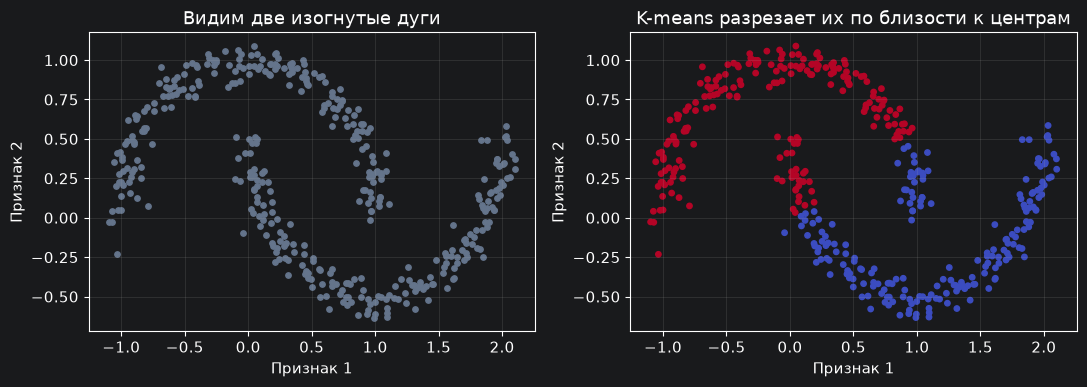

In [25]:
print("Среднее [1, 2, 3]:", np.mean([1, 2, 3]))
print("Среднее [1, 2, 3, 100]:", np.mean([1, 2, 3, 100]))

X_moons, _ = make_moons(n_samples=400, noise=0.065, random_state=SEED)
moons_scaler = StandardScaler()
X_moons_scaled = moons_scaler.fit_transform(X_moons)
moon_km = KMeans(n_clusters=2, n_init=10, random_state=SEED)
moon_km_labels = moon_km.fit_predict(X_moons_scaled)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], s=15, color="#64748b")
axes[0].set_title("Видим две изогнутые дуги")
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=moon_km_labels, cmap="coolwarm", s=15)
axes[1].set_title("K-means разрезает их по близости к центрам")
for ax in axes:
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")
plt.tight_layout()
plt.show()

**Вывод:** неверно говорить, что K-means «сломался». Он оптимизирует своё правило компактности вокруг центров.
Для дуг нам нужно другое правило: плотная цепочка соседей.

Це не є помилка K-means, оскільки алгортим мінімізує суму квадратів відстаней від кожної точки до найближчого центру, а точки з однієї дуги мождуть бути ближче до точок іншої дуги, ніж до протилежного кінця своєї власної. А, так як центри розташовуються приблезно в центрі кожної дуги, межа між кластерами пройде через середину переплетення, а не по формі дуг. Частина верхньої увійде до нижнього кластеру. Так само працює навпаки.

Замість K-means варто було б використати алгортим у розділі 7, що дивитьься на щільність точок у околі кожної точки, а не на відстані між центрами.

## 7. DBSCAN на четырёх точках: core, border, noise
Точки `[0, 0.1, 0.2, 2.0]`, радиус `eps=0.15`, минимум `min_samples=3`.
Сама точка тоже учитывается в числе соседей.
- У 0.1 три соседа вместе с ней самой: это **core**, центральная точка.
- 0 и 0.2 — **border**, граничные: рядом есть core, но своих соседей мало.
- 2.0 — **noise**, шум: метка `-1`.

In [26]:
X_tiny = np.array([0., 0.1, 0.2, 2.0]).reshape(-1, 1)
tiny_db = DBSCAN(eps=0.15, min_samples=3).fit(X_tiny)
is_core = np.zeros(len(X_tiny), dtype=bool)
is_core[tiny_db.core_sample_indices_] = True
tiny_dist = np.abs(X_tiny - X_tiny.T)
neighbors_count = (tiny_dist <= 0.15).sum(axis=1)
roles = np.where(tiny_db.labels_ == -1, "шум", np.where(is_core, "core", "граница"))
print(pd.DataFrame({"Точка": X_tiny.ravel(), "Соседи (с собой)": neighbors_count,
                    "Метка": tiny_db.labels_, "Роль": roles}).to_string(index=False))
assert list(roles) == ["граница", "core", "граница", "шум"]

 Точка  Соседи (с собой)  Метка    Роль
   0.0                 2      0 граница
   0.1                 3      0    core
   0.2                 2      0 граница
   2.0                 1     -1     шум


Группа расширяется через core-точки. Граничная точка входит в группу, но сама цепочку не продолжает.
`eps` — радиус окрестности, а не диаметр всего кластера.

## 8. DBSCAN на дугах и изменение радиуса
Визуализируем шум серыми крестиками, чтобы `-1` не выглядел обычной группой.

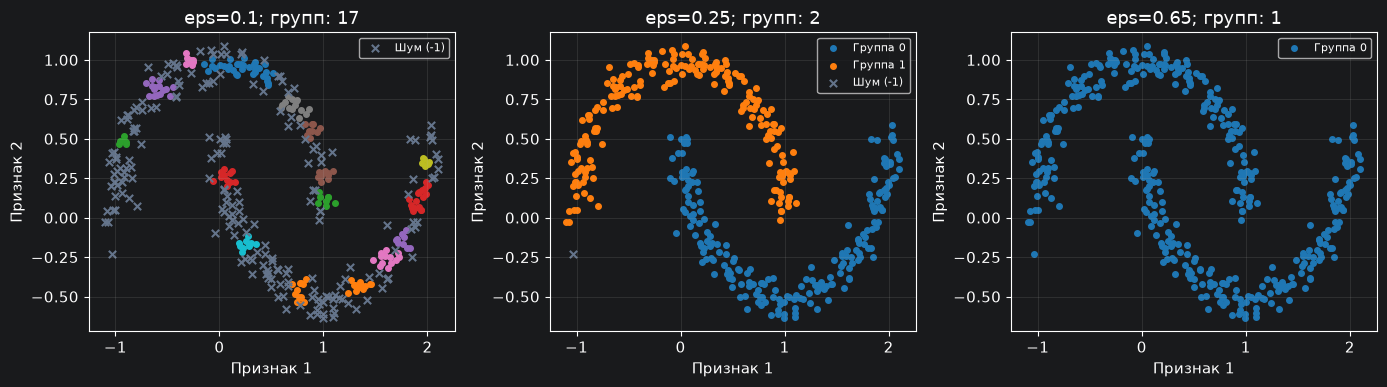

 eps  Кластеры  Шум, объектов  Шум, %
0.10        17            203    50.7
0.25         2              1     0.2
0.65         1              0     0.0


In [27]:
def draw_clusters(ax, X, labels, title):
    groups = sorted(set(labels) - {-1})
    palette = plt.get_cmap("tab10")
    for position, group in enumerate(groups):
        mask = labels == group
        ax.scatter(X[mask, 0], X[mask, 1], s=16,
                   color=palette(position % 10), label=f"Группа {group}" if len(groups) <= 5 else "_nolegend_")
    noise = labels == -1
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], color="#64748b", marker="x", s=28, label="Шум (-1)")
    ax.set(title=title, xlabel="Признак 1", ylabel="Признак 2")
    if len(groups) <= 5 or noise.any():
        ax.legend(fontsize=8, loc="best")

radius_values = [0.10, 0.25, 0.65]
db_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, radius in zip(axes, radius_values):
    labels = DBSCAN(eps=radius, min_samples=6).fit_predict(X_moons_scaled)
    groups_count = len(set(labels) - {-1})
    db_rows.append({"eps": radius, "Кластеры": groups_count,
                    "Шум, объектов": int((labels == -1).sum()),
                    "Шум, %": round(100 * np.mean(labels == -1), 1)})
    draw_clusters(ax, X_moons, labels, f"eps={radius}; групп: {groups_count}")
plt.tight_layout()
plt.show()
print(pd.DataFrame(db_rows).to_string(index=False))

**Что обсудить:** при малом радиусе много объектов не входят в плотные группы;
при подходящем видны дуги; при слишком большом они могут слиться.
Если немного изменить шум данных, подходящий радиус тоже может измениться.

При eps=0.10 створено 18 кластерів, 50.7% шуму. Радіус у 0.10 є замалим, щоб захопити всі сусідні точки дуг, а, оскільки більшість точок мають менше ніж 6 сусдів у радіусі 0.10, то вонги стають шумом, або просто утворюють дрібні локальні кластери з 6-10 точок.

При eps=0.25 створено 2 кластери, 0.2% шуму. Радіус у 0.25 є достатнім, щоб у кожній точці дуги було не строго більше 6 сусідів. Кластери ростуть уздовж дуг, утворюючи два кластери. Всі точки задіяні, крім однієї.

При eps=0.65 створено 1 кластер, 0% шуму. Радіус у 0.65 є занадто велкиим, адже тепер кожна точка бачить сусідів з іншої дуги, через що вони обидві створили один щільний кластер, а алгоитм не розрізняє їх.

Отже, eps залежитться від даних. Якщо збільшити шум, точки стануть далі одна від одної, і для тих самих 2 дуг потрібно буде робити більший eps. А якщо зменшити масштаю ознак - треба буде зменшити eps.

## 9. Осторожно с метриками DBSCAN
Нельзя бездумно сравнивать silhouette K-means на всех точках с DBSCAN только на нескольких удобных точках.
Ниже исключаем шум для метрики, отдельно показываем долю оставшихся данных и проверяем допустимость расчёта.
Высокая оценка компактности не гарантирует правильное выделение изогнутых дуг.

In [28]:
metric_rows = []
for radius in [0.10, 0.18, 0.25, 0.65]:
    labels = DBSCAN(eps=radius, min_samples=6).fit_predict(X_moons_scaled)
    keep = labels != -1
    n_kept = int(keep.sum())
    n_groups = len(set(labels[keep]))
    value = (silhouette_score(X_moons_scaled[keep], labels[keep])
             if 2 <= n_groups < n_kept else np.nan)
    metric_rows.append({"eps": radius, "Групп без шума": n_groups,
                       "Осталось, %": 100 * keep.mean(), "Silhouette без шума": value})
print(pd.DataFrame(metric_rows).round(3).to_string(index=False))
print("NaN означает: для этого разбиения метрика не определена.")

 eps  Групп без шума  Осталось, %  Silhouette без шума
0.10              17        49.25                0.643
0.18               3        97.75                0.075
0.25               2        99.75                0.381
0.65               1       100.00                  NaN
NaN означает: для этого разбиения метрика не определена.


## 10. RFM: из заказов в одну строку на клиента
Дата анализа — **1 июня 2026 года**. У клиента 101 два заказа: 10 мая на 300 и 30 мая на 500.
Первый заказ разбит на две товарные строки, поэтому строк три, но заказов два.
Ожидаем: **Recency=2 дня, Frequency=2 заказа, Monetary=800 условных денежных единиц**.

In [29]:
analysis_date = pd.Timestamp("2026-06-01")
tiny_orders = pd.DataFrame([
    [101, "A-1", "2026-05-10", 1, 100],
    [101, "A-1", "2026-05-10", 2, 100],
    [101, "A-2", "2026-05-30", 1, 500],
], columns=["CustomerID", "OrderID", "OrderDate", "Quantity", "UnitPrice"])
tiny_orders["OrderDate"] = pd.to_datetime(tiny_orders["OrderDate"])
tiny_orders["Revenue"] = tiny_orders["Quantity"] * tiny_orders["UnitPrice"]
print(tiny_orders.to_string(index=False))

def build_rfm(transactions, snapshot):
    # Учебные данные: положительные продажи, без возвратов и отмен.
    assert transactions["CustomerID"].notna().all()
    assert (transactions["OrderDate"] < snapshot).all()
    result = transactions.groupby("CustomerID").agg(
        LastPurchase=("OrderDate", "max"),
        Frequency=("OrderID", "nunique"),
        Monetary=("Revenue", "sum"),
    )
    result["Recency"] = (snapshot - result["LastPurchase"]).dt.days
    return result[["Recency", "Frequency", "Monetary"]]

rfm_tiny = build_rfm(tiny_orders, analysis_date)
print("\nRFM:")
print(rfm_tiny.to_string())
assert rfm_tiny.loc[101].tolist() == [2, 2, 800]

 CustomerID OrderID  OrderDate  Quantity  UnitPrice  Revenue
        101     A-1 2026-05-10         1        100      100
        101     A-1 2026-05-10         2        100      200
        101     A-2 2026-05-30         1        500      500

RFM:
            Recency  Frequency  Monetary
CustomerID                              
101               2          2       800


`groupby` собирает строки одного клиента. `max` находит последнюю дату,
`nunique` считает разные номера заказов, `sum` складывает выручку.
Recency измеряется в днях от фиксированной даты анализа, не от текущего дня запуска.

## 11. Учебные клиенты: обработка, кластеры, интерпретация
Создадим историю покупок за последние 180 дней для 120 клиентов.
Четыре режима поведения встроены в генератор **только для демонстрации**.
Их названия не передаются модели. В реальном магазине число и форма групп заранее неизвестны.

In [30]:
rng = np.random.default_rng(SEED)
records = []
# Для каждой группы: диапазон давности, числа заказов и типичной суммы заказа.
profiles = [((1, 15), (14, 24), 420),
            ((3, 25), (6, 11), 180),
            ((1, 18), (1, 3), 90),
            ((90, 150), (2, 5), 110)]
customer_id = 1000
for recency_range, count_range, typical_bill in profiles:
    for _ in range(30):
        customer_id += 1
        latest_days = int(rng.integers(*recency_range))
        count = int(rng.integers(*count_range))
        ages = [latest_days] + rng.integers(latest_days + 1, 180, size=count - 1).tolist()
        for order_index, days_ago in enumerate(ages, start=1):
            revenue = round(float(rng.lognormal(np.log(typical_bill), 0.25)), 2)
            records.append([customer_id, f"{customer_id}-{order_index}",
                            analysis_date - pd.Timedelta(days=int(days_ago)), revenue])
transactions = pd.DataFrame(records, columns=["CustomerID", "OrderID", "OrderDate", "Revenue"])
rfm = build_rfm(transactions, analysis_date)
print("Клиентов:", len(rfm), "Заказов:", len(transactions))
print(rfm.head(8).round(2).to_string())
print("\nПределы признаков:")
print(rfm.agg(["min", "median", "max"]).round(2).to_string())

Клиентов: 120 Заказов: 928
            Recency  Frequency  Monetary
CustomerID                              
1001              2         21   9495.40
1002              6         17   7405.66
1003              7         20   8106.39
1004              4         18   7255.20
1005             10         18   7817.08
1006              3         23  10024.23
1007             10         16   7121.37
1008              4         15   6408.00

Пределы признаков:
        Recency  Frequency  Monetary
min         1.0        1.0     57.28
median     11.0        5.0    701.51
max       146.0       23.0  10410.75


### 11.1. Подготовка признаков
`log1p(x) = ln(1 + x)` уменьшает разрыв между обычными и очень большими значениями.
Здесь применим его ко всем трём неотрицательным признакам как учебный вариант, затем стандартизируем.
CustomerID не используем: это идентификатор, а не поведение.

 K  Silhouette
 2       0.565
 3       0.666
 4       0.672
 5       0.639
 6       0.607

Профили в исходных единицах (дни / заказы / деньги):
         Clients  Recency_median  Frequency_median  Monetary_median
Cluster                                                            
0             30            12.5               8.0           1536.0
1             30            10.5               1.0            112.4
2             30             7.0              18.0           7810.9
3             30           118.5               3.0            329.5


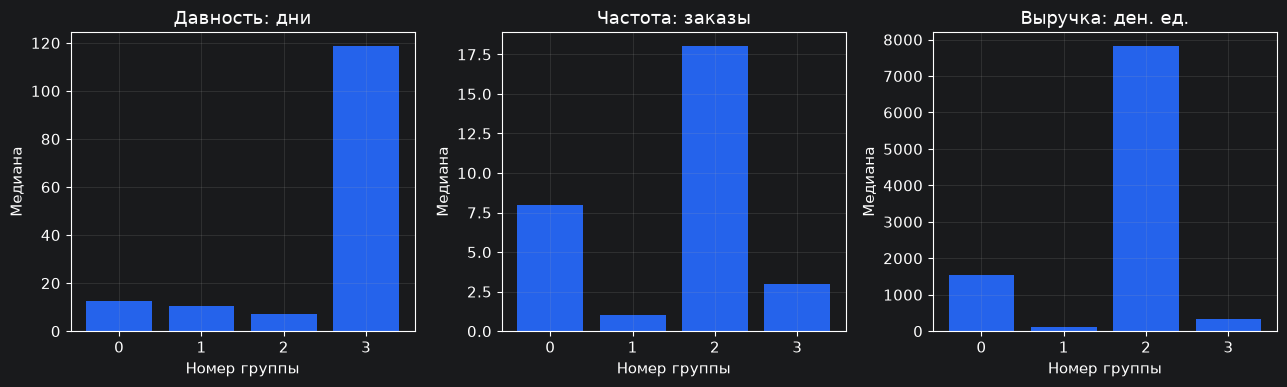

In [31]:
rfm_features = ["Recency", "Frequency", "Monetary"]
rfm_scaler = StandardScaler()
rfm_scaled = rfm_scaler.fit_transform(np.log1p(rfm[rfm_features]))
rfm_scores = []
for k in range(2, 7):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = candidate.fit_predict(rfm_scaled)
    rfm_scores.append({"K": k, "Silhouette": silhouette_score(rfm_scaled, labels)})
print(pd.DataFrame(rfm_scores).round(3).to_string(index=False))

# K=4 — открытое учебное решение для разбора четырёх профилей генератора.
# Метрика и бизнес-цель на реальных данных могут привести к другому выбору.
rfm_model = KMeans(n_clusters=4, n_init=10, random_state=SEED)
rfm["Cluster"] = rfm_model.fit_predict(rfm_scaled)
profile = rfm.groupby("Cluster").agg(
    Clients=("Recency", "size"),
    Recency_median=("Recency", "median"),
    Frequency_median=("Frequency", "median"),
    Monetary_median=("Monetary", "median"),
)
print("\nПрофили в исходных единицах (дни / заказы / деньги):")
print(profile.round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, feature, title in zip(axes, ["Recency_median", "Frequency_median", "Monetary_median"],
                              ["Давность: дни", "Частота: заказы", "Выручка: ден. ед."]):
    ax.bar(profile.index.astype(str), profile[feature], color="#2563eb")
    ax.set(title=title, xlabel="Номер группы", ylabel="Медиана")
plt.tight_layout()
plt.show()

### 11.2. Проверяем, не зависит ли вывод от случайного старта
ARI сравнивает два разбиения с учётом того, что номера кластеров могут переставиться.
ARI=1 означает одинаковое разбиение с точностью до переименования. Это проверка устойчивости, не истинности сегментов.

In [32]:
alternative_labels = KMeans(n_clusters=4, n_init=10, random_state=7).fit_predict(rfm_scaled)
print("Сходство двух разбиений, ARI:", round(adjusted_rand_score(rfm["Cluster"], alternative_labels), 3))
print("\nТри клиента с максимальной выручкой в каждой группе:")
top_clients = (rfm.sort_values("Monetary", ascending=False)
              .groupby("Cluster", group_keys=False).head(3).sort_values("Cluster"))
print(top_clients.round(1).to_string())

Сходство двух разбиений, ARI: 1.0

Три клиента с максимальной выручкой в каждой группе:
            Recency  Frequency  Monetary  Cluster
CustomerID                                       
1042             24         10    2118.0        0
1045             23         10    1956.8        0
1036              6         10    1894.6        0
1088              1          2     238.0        1
1072             14          2     215.9        1
1083             11          2     211.2        1
1006              3         23   10024.2        2
1028              2         23   10410.8        2
1019             10         22   10031.8        2
1115            120          4     586.6        3
1106            113          4     526.3        3
1105             94          4     446.2        3
